# HPC post-processing template

In [1]:
# Specify folder with output files and name of combined file here
top_folder = "/Users/seanmullane/Desktop/Research_2023/HPC/High_Hx_Test/ten_output_test"
combined_file_name = "test_output.csv"

In [2]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "../")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [3]:
# Number of bins and dosing grid half-length - both set in TOPAS parameter files
bins_mosh = 85
dose_grid_half_mosh = 2.5 #2.125 # cm

# Z coordinate of radioactive source - set in TOPAS parameter files
source_transZ_mosh = -0.5 # cm

# Applicator radius - set in TOPAS parameter files
applicator_rad = 0.3

# Computes the lattice length for the simulation space in cm
lattice_mosh = dose_grid_half_mosh*2/bins_mosh

In [4]:
# Assume dose point in center of ROI
dose_point = (0.0, 0.5)

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] # cm

# 0 = x, 1 = y, 2 = z
const_axis = 2

# Set the range of our contour plots
# Maximum range set by TOPAS parameter files
rngX = (-1.5, 1.5)
rngY = (-1.5, 1.5)

dose = 100 # % of dose
# Compute the plane of the source
source_plane = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, lattice_mosh)

In [5]:
# Generate list of output files
for dirpath, __, filenames in os.walk(top_folder):
    output_files = [dirpath + "/" + x for x in filenames]

In [6]:
# Combine the output files into a single file and run normal post-processing
total_energy = combine_files(output_files, save_file=True, file_name=combined_file_name)

dose_point_energy, dose_point_voxel = extract_norm_energy(combined_file_name, source_plane, const_axis, dose_point, bins_mosh, lattice_mosh)
X, Y, energy1, std_dev = contour_energy(combined_file_name, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       source_rad=source_rad[4], scale=True, norm_energy=dose_point_energy, dose=dose, zero_source=True, std_dev=True)

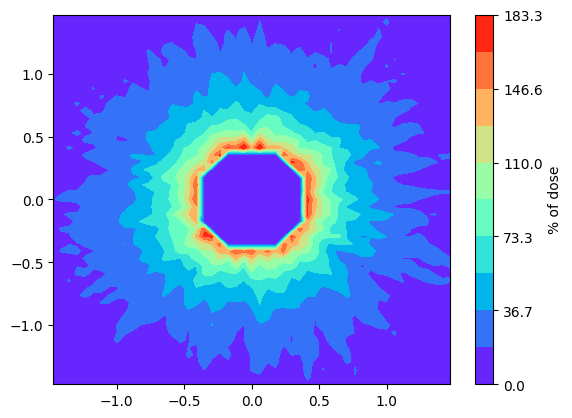

In [7]:
# Construct and draw basic contour plot
fig2, ax2 = plt.subplots()
Xv, Yv = np.meshgrid(X, Y, indexing='ij') # this indexing is important - otherwise contour plot will be rotated

contour2 = ax2.contourf(Xv, Yv, energy1, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar2 = fig2.colorbar(contour2, label="% of dose")

### Danger zone - delete the original output files

In [ ]:
# Use this function with EXTREME CAUTION. It will delete the directory top_folder once you have combined all the output files.
# Do not use this function until you are sure that you do not need the original 1e3 output files. 
# We recommend testing the file created by the function combine_files above to verify that data was stored correctly.
# In addition, you should double check that top_folder is the correct directory to delete before running.
# For example, if you run this function with top_folder = "/", it will delete ALL FILES ON YOUR COMPUTER.
###########################
#os.rmdir(top_folder) # uncomment to delete - have you double-checked that top_folder is the correct directory?
###########################